# Detection of Iris flower species

The iris flower dataset is a multivariate dataset is a multivariate dataset prepared by the british statistician and biologist Ronald Fisher. The dataset consists of 50 samples each from the three species of Iris- Setosa, virginica, and versicolor. 

Four features were measured, in centemiters from each sample - the length and the width of the sepals and petals. 
    This implementation program has been developed in Python. In this case, a Decision tree model is trained to classfiy whether an iris flower belongs
to either of the species 'setosa', 'virginica'. The Decision Tree algorithm is a widely used model in machine learning for classficitaion tasks. 

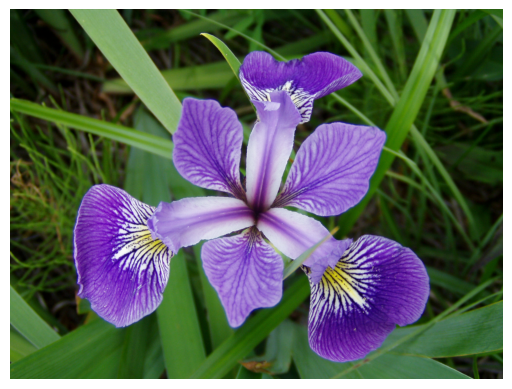

In [1]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
images = mpimg.imread("Iris_versicolor_3.jpg")
plt.imshow(images)
plt.axis("off")
plt.show()

To start with, a new python file was created. The implementation consists of two salient parts : 
   i.) A machine learning part for predicting the species of iris flower.
  ii.) A GUI(Graphical User Interface) application that allows user to input the features of an iris flower and recive a prediction result.

# Model Prepration for species prediction 

First, let's import all neccessary libraies. we will need the following libraries:
 - Sklearn libary for the different machine learning related functionalities. The iris dataset can also be obtained from the sklearn library.
 - Joblib library for saving the trained model as .pkl(also called 'pickle' file)

In [2]:
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.datasets import load_iris
import joblib

# Define a function build_model() to do the following

- load iris dataset using the sklearn load_iris() function
- split the dataset into two portions- train and test
- test datasized is assumed to be 30% of the overall dataset and 70% goes for trained the model. 
- The decision tree is adopted here.
- Train the decision tree model with the training data samples
- at the end, save the trained model as iris_model.pkl file so that it can be used fat a later point in time.

In [3]:
iris = load_iris()
print(iris)

{'data': array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2],
       [4.6, 3.1, 1.5, 0.2],
       [5. , 3.6, 1.4, 0.2],
       [5.4, 3.9, 1.7, 0.4],
       [4.6, 3.4, 1.4, 0.3],
       [5. , 3.4, 1.5, 0.2],
       [4.4, 2.9, 1.4, 0.2],
       [4.9, 3.1, 1.5, 0.1],
       [5.4, 3.7, 1.5, 0.2],
       [4.8, 3.4, 1.6, 0.2],
       [4.8, 3. , 1.4, 0.1],
       [4.3, 3. , 1.1, 0.1],
       [5.8, 4. , 1.2, 0.2],
       [5.7, 4.4, 1.5, 0.4],
       [5.4, 3.9, 1.3, 0.4],
       [5.1, 3.5, 1.4, 0.3],
       [5.7, 3.8, 1.7, 0.3],
       [5.1, 3.8, 1.5, 0.3],
       [5.4, 3.4, 1.7, 0.2],
       [5.1, 3.7, 1.5, 0.4],
       [4.6, 3.6, 1. , 0.2],
       [5.1, 3.3, 1.7, 0.5],
       [4.8, 3.4, 1.9, 0.2],
       [5. , 3. , 1.6, 0.2],
       [5. , 3.4, 1.6, 0.4],
       [5.2, 3.5, 1.5, 0.2],
       [5.2, 3.4, 1.4, 0.2],
       [4.7, 3.2, 1.6, 0.2],
       [4.8, 3.1, 1.6, 0.2],
       [5.4, 3.4, 1.5, 0.4],
       [5.2, 4.1, 1.5, 0.1],
       [5.5, 4.2, 1.4, 0.2],
     

In [4]:
# convert iris dataset into Pandas Dataframe.

In [5]:
import pandas as pd
df = pd.DataFrame(iris.data, columns= iris.feature_names)
df["Species"] = iris.target

In [6]:
print(df)

     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                  5.1               3.5                1.4               0.2   
1                  4.9               3.0                1.4               0.2   
2                  4.7               3.2                1.3               0.2   
3                  4.6               3.1                1.5               0.2   
4                  5.0               3.6                1.4               0.2   
..                 ...               ...                ...               ...   
145                6.7               3.0                5.2               2.3   
146                6.3               2.5                5.0               1.9   
147                6.5               3.0                5.2               2.0   
148                6.2               3.4                5.4               2.3   
149                5.9               3.0                5.1               1.8   

     Species  
0          0

In [7]:
# Here, In species columns(0,1,2) defines for different species name 'setosa', 'versicolor', 'virginica'.
# so, let's replace 0,1,2 with thier original name.

In [8]:
df["Species"] = df["Species"].map({
    0: "Setosa",
    1: "Versicolor",
    2: "Virginica"
})

In [9]:
df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Virginica
146,6.3,2.5,5.0,1.9,Virginica
147,6.5,3.0,5.2,2.0,Virginica
148,6.2,3.4,5.4,2.3,Virginica


In [10]:
def build_model():
    # Load Dataset
    iris = load_iris()
    
    X,y = iris.data, iris.target
    # x: Input Features
    # y : Predictions(Correct flower Species)

    # Split dataset into training set and test set
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.3, random_state= 1)
    # Random_state: "Every execution produces the same split, provided the data and other settings remain unchanged".
    # With random State every split is same.

    # Create Decision Tree Classifer object 
    clf = DecisionTreeClassifier()

    # Train Decision Tree Classifer 
    clf = clf.fit(X_train, y_train)

    # Save the model to disk
    joblib.dump(clf, 'iris_model.pkl')
    

# BUILDING GUI APPLICATION FOR USER INPUT AND PREDICTION

Once the model is trained and the model file is saved for the future use, then the next step is to develop a simple GUI to take user inputs related to 
the feature values of a new iris flower. 
    As we know, the user inputs are needed for four features, namely speal length, sepal width, petal length, and petal width. Through there are 
multiple options for building GUI in Python, we will start use the "Tkinter" library for the GUI front end. 

In [11]:
# Let's first import the Tkinter library.

In [12]:
import tkinter as tk
from tkinter import messagebox

After that, define a function show_dialogue() to do the following:
- load the trained model from iris_model.pkl.file
- Create the dialogue box for taking user inputs using Tkinter library widgest e.g., Label, Entry box, Button
- define a sub-fuction classdify() which picks the user inputs from the Entry boxes and use them to generate prediction from the trained model.
- the function classify() is invoked when the Button is clicked

In [13]:
def show_dialogue():

    # Load the trained model
    model = joblib.load("iris_model.pkl")

    # Load Dataset
    iris = load_iris()

    def classify():
        try:
            sepal_length = float(sepal_length_entry.get())
            sepal_width = float(sepal_width_entry.get())
            petal_length = float(petal_length_entry.get())
            petal_width = float(petal_width_entry.get())

            features = [sepal_length, sepal_width, petal_length, petal_width]

            result = iris.target_names[model.predict([features])[0]]

            messagebox.showinfo("Result", f"The Iris flower is classified as: {result}")

        except ValueError:
            messagebox.showerror("Error", "Please Enter Valid Numbers")

    app = tk.Tk()
    app.title("Iris Flower Classification")

    tk.Label(app, text="Sepal Length (cm):").grid(row=0, column=0, padx=10, pady=10)
    sepal_length_entry = tk.Entry(app)
    sepal_length_entry.grid(row=0, column=1, padx=10, pady=10)

    tk.Label(app, text="Sepal Width (cm):").grid(row=1, column=0, padx=10, pady=10)
    sepal_width_entry = tk.Entry(app)
    sepal_width_entry.grid(row=1, column=1, padx=10, pady=10)

    tk.Label(app, text="Petal Length (cm):").grid(row=2, column=0, padx=10, pady=10)
    petal_length_entry = tk.Entry(app)
    petal_length_entry.grid(row=2, column=1, padx=10, pady=10)

    tk.Label(app, text="Petal Width (cm):").grid(row=3, column=0, padx=10, pady=10)
    petal_width_entry = tk.Entry(app)
    petal_width_entry.grid(row=3, column=1, padx=10, pady=10)

    classify_btn = tk.Button(app, text="Classify", command=classify)
    classify_btn.grid(row=4, column=0, columnspan=2, pady=20)

    app.mainloop()

In [ ]:
# Define main function
if __name__ == "__main__":
    build_model()
    show_dialogue()